Device: cuda
GPU   : Tesla T4
=== Path Check ===
  OK      S1Hand     → /kaggle/input/datasets/smabrarrajin/sen1floods11-essentials/v1.2/data/flood_events/HandLabeled/S1Hand
  OK      LabelHand  → /kaggle/input/datasets/smabrarrajin/sen1floods11-essentials/v1.2/data/flood_events/HandLabeled/LabelHand

Converting per-pixel masks → image labels (flooded = water fraction ≥ 0.01) ...
  Chips: 441 (293 flooded | 148 non-flooded)
Split: train 220 (146 flooded) | valid 221 (147 flooded)

Dense resnet18: 11.18M params | 8.94 GFLOPs @ 400×300
Training dense resnet18 | 50 epochs | SGD lr=0.01 ...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s] 


    dense ep  1/50 │ loss  0.7892 │ acc 0.6652 │ f1 0.7989 │ auc 0.7792
    dense ep  2/50 │ loss  0.7323 │ acc 0.7511 │ f1 0.8387 │ auc 0.8430
    dense ep  3/50 │ loss  0.5412 │ acc 0.4887 │ f1 0.3957 │ auc 0.8415
    dense ep  4/50 │ loss  0.5265 │ acc 0.6878 │ f1 0.7137 │ auc 0.8704
    dense ep  5/50 │ loss  0.4907 │ acc 0.7149 │ f1 0.7449 │ auc 0.8783
    dense ep  6/50 │ loss  0.4091 │ acc 0.8371 │ f1 0.8784 │ auc 0.8879
    dense ep  7/50 │ loss  0.3318 │ acc 0.8416 │ f1 0.8772 │ auc 0.8879
    dense ep  8/50 │ loss  0.3696 │ acc 0.8190 │ f1 0.8750 │ auc 0.8997
    dense ep  9/50 │ loss  0.3508 │ acc 0.8190 │ f1 0.8551 │ auc 0.9025
    dense ep 10/50 │ loss  0.3213 │ acc 0.6923 │ f1 0.7119 │ auc 0.8946
    dense ep 11/50 │ loss  0.3120 │ acc 0.8462 │ f1 0.8903 │ auc 0.9035
    dense ep 12/50 │ loss  0.3657 │ acc 0.8507 │ f1 0.8932 │ auc 0.9100
    dense ep 13/50 │ loss  0.2633 │ acc 0.8462 │ f1 0.8910 │ auc 0.9104
    dense ep 14/50 │ loss  0.2851 │ acc 0.8371 │ f1 0.8705 │ auc

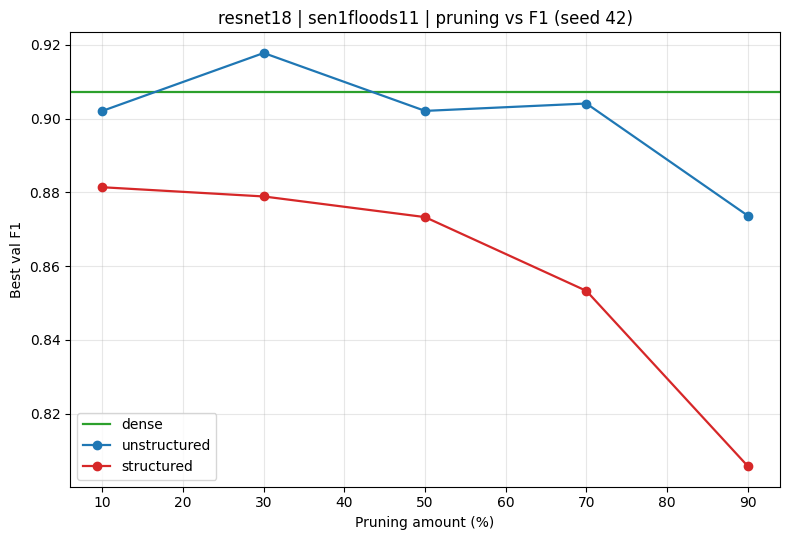

Saved → resnet18_sen1floods11_prune_plot.png

✓ All done.


In [2]:
import os, copy, random, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from pathlib import Path
import rasterio
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.utils.prune as prune
import torchvision
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
)
import matplotlib.pyplot as plt

# ── 0. Knobs (IDENTICAL across both datasets — lead's requirement) ─────
MODEL_NAME = "resnet18"
DATASET    = "sen1floods11"
SEED       = 42                                  # training + split seed
LEVELS     = [0.10, 0.30, 0.50, 0.70, 0.90]      # lead's 5 ratios
METHODS    = ["unstructured", "structured"]      # trim if only one needed
E          = 50                                  # dense epochs
FT_EPOCHS  = 50                                  # fine-tune epochs
LR         = 0.01                                # SGD, no momentum
BATCH      = 64 if MODEL_NAME == "resnet18" else 16
IMG_W, IMG_H = 400, 300
FLOOD_THRESHOLD = 0.01     # chip flooded if ≥1% of valid pixels are water

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
TAG = f"{MODEL_NAME}_{DATASET}"
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda": print(f"GPU   : {torch.cuda.get_device_name(0)}")

# ── 1. Locate SEN1FLOODS11 ─────────────────────────────────────────────
ROOT = Path("/kaggle/input/sen1floods11-essentials")
if not ROOT.exists():
    import kagglehub
    ROOT = Path(kagglehub.dataset_download(
        "smabrarrajin/sen1floods11-essentials"))

def find_dir(root, target_name):
    for dirpath, dirnames, _ in os.walk(root):
        for d in dirnames:
            if d.lower() == target_name.lower():
                return Path(dirpath) / d
    return None

S1_DIR    = find_dir(ROOT, "S1Hand")
LABEL_DIR = find_dir(ROOT, "LabelHand")
print("=== Path Check ===")
for name, p in [("S1Hand", S1_DIR), ("LabelHand", LABEL_DIR)]:
    print(f"  {'OK' if p else 'MISSING':7} {name:<10} → {p}")
assert S1_DIR is not None and LABEL_DIR is not None

# ── 2. Pixel masks → IMAGE-LEVEL labels ────────────────────────────────
def water_fraction(mask_path):
    with rasterio.open(mask_path) as src:
        m = src.read(1)
    valid = m != -1
    if not valid.any(): return None
    return float((m[valid] == 1).mean())

print(f"\nConverting per-pixel masks → image labels "
      f"(flooded = water fraction ≥ {FLOOD_THRESHOLD:.2f}) ...")
X, y = [], []
for mask_path in sorted(LABEL_DIR.glob("*.tif")):
    stem    = mask_path.name.replace("_LabelHand.tif", "")
    s1_path = S1_DIR / f"{stem}_S1Hand.tif"
    if not s1_path.exists(): continue
    wf = water_fraction(mask_path)
    if wf is None: continue
    X.append(str(s1_path)); y.append(int(wf >= FLOOD_THRESHOLD))
print(f"  Chips: {len(X)} ({sum(y)} flooded | {len(y)-sum(y)} non-flooded)")

# ── 3. 50/50 stratified split (same as ResNet18 reference run) ─────────
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, train_size=0.5, stratify=y, random_state=SEED)
print(f"Split: train {len(X_train)} ({sum(y_train)} flooded) | "
      f"valid {len(X_valid)} ({sum(y_valid)} flooded)")
assert sum(y_valid) > 0 and sum(y_valid) < len(y_valid), \
    "Validation set must contain BOTH classes."

# ── 4. SAR chip → 3-channel tensor at 300×400 / loaders ────────────────
DB_MIN, DB_MAX = -50.0, 1.0
IMAGENET_MEAN  = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD   = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def load_s1_tensor(path):
    with rasterio.open(path) as src:
        arr = src.read().astype(np.float32)
    arr = np.nan_to_num(arr, nan=DB_MIN)
    arr = np.clip(arr, DB_MIN, DB_MAX)
    arr = (arr - DB_MIN) / (DB_MAX - DB_MIN)
    vv, vh = arr[0], arr[1]
    img = np.stack([vv, vh, (vv + vh) / 2.0])
    t = torch.from_numpy(img)
    t = F.interpolate(t.unsqueeze(0), size=(IMG_H, IMG_W),
                      mode="bilinear", align_corners=False).squeeze(0)
    return (t - IMAGENET_MEAN) / IMAGENET_STD

class S1Dataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = X, y, augment
    def __len__(self): return len(self.X)
    def __getitem__(self, idx):
        t = load_s1_tensor(self.X[idx])
        if self.augment:
            if random.random() < 0.5: t = torch.flip(t, dims=[2])  # horiz
            if random.random() < 0.5: t = torch.flip(t, dims=[1])  # vert
        return t, self.y[idx]

_, counts      = np.unique(y_train, return_counts=True)
class_weights  = [1.0/c for c in counts]
sample_weights = [class_weights[l] for l in y_train]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights),
                                replacement=True)

train_ldr = DataLoader(S1Dataset(X_train, y_train, augment=True),
                       batch_size=BATCH, sampler=sampler,
                       num_workers=2, pin_memory=True)
valid_ldr = DataLoader(S1Dataset(X_valid, y_valid),
                       batch_size=BATCH, shuffle=False,
                       num_workers=2, pin_memory=True)

# ── 5. Model builder ───────────────────────────────────────────────────
def build_model(pretrained=True):
    if MODEL_NAME == "resnet18":
        w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        m = torchvision.models.resnet18(weights=w)
        m.fc = nn.Linear(m.fc.in_features, 2)
    else:
        w = torchvision.models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None
        m = torchvision.models.vgg16(weights=w)
        m.classifier[-1] = nn.Linear(4096, 2)
    return m

# ── 6. Params & MACs profiler (hook-based) ─────────────────────────────
def profile_model(model):
    model = model.to("cpu").eval()
    macs_total, per_layer, hooks = {"v": 0}, {}, []
    def conv_hook(name):
        def fn(mod, inp, out):
            k = mod.kernel_size[0] * mod.kernel_size[1]
            macs = out.numel() * (mod.in_channels // mod.groups) * k
            macs_total["v"] += macs; per_layer[name] = macs
        return fn
    def lin_hook(name):
        def fn(mod, inp, out):
            macs = mod.in_features * mod.out_features
            macs_total["v"] += macs; per_layer[name] = macs
        return fn
    for name, mod in model.named_modules():
        if isinstance(mod, nn.Conv2d):
            hooks.append(mod.register_forward_hook(conv_hook(name)))
        elif isinstance(mod, nn.Linear):
            hooks.append(mod.register_forward_hook(lin_hook(name)))
    with torch.no_grad():
        model(torch.randn(1, 3, IMG_H, IMG_W))
    for h in hooks: h.remove()
    n_params = sum(p.numel() for p in model.parameters())
    return n_params, macs_total["v"], per_layer

def count_nonzero_params(model):
    total, nonzero = 0, 0
    for p in model.parameters():
        total += p.numel(); nonzero += int((p != 0).sum().item())
    return total, nonzero

def effective_macs(model, per_layer_macs):
    eff, named = 0, dict(model.named_modules())
    for lname, macs in per_layer_macs.items():
        mod = named.get(lname)
        if mod is None: eff += macs; continue
        w = mod.weight.detach()
        eff += macs * float((w != 0).sum().item()) / max(w.numel(), 1)
    return eff

# ── 7. Evaluation ──────────────────────────────────────────────────────
def evaluate(model, loader):
    model.eval()
    probs_all, preds_all, lbls_all = [], [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            out   = model(imgs.to(DEVICE))
            probs = torch.softmax(out, 1)[:, 1].cpu().numpy()
            preds = out.argmax(1).cpu().numpy()
            probs_all.extend(probs); preds_all.extend(preds)
            lbls_all.extend(np.asarray(lbls))
    acc  = accuracy_score(lbls_all, preds_all)
    f1   = f1_score(lbls_all,       preds_all, zero_division=0)
    prec = precision_score(lbls_all, preds_all, zero_division=0)
    rec  = recall_score(lbls_all,   preds_all, zero_division=0)
    try:    roc = roc_auc_score(lbls_all, probs_all)
    except: roc = float("nan")
    return acc, f1, prec, rec, roc

# ── 8. Training loop (keeps best-F1 checkpoint) ────────────────────────
def train_loop(model, epochs, tag=""):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=LR)
    best_f1, best_epoch, best_state, best_metrics = -1, -1, None, None
    for ep in range(epochs):
        model.train()
        total_loss, n_b = 0.0, 0
        for imgs, lbls in train_ldr:
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(imgs), lbls)
            loss.backward(); optimizer.step()
            total_loss += loss.item(); n_b += 1
        acc, f1, prec, rec, roc = evaluate(model, valid_ldr)
        print(f"    {tag} ep {ep+1:2d}/{epochs} │ "
              f"loss {total_loss/max(n_b,1):7.4f} │ acc {acc:.4f} │ "
              f"f1 {f1:.4f} │ auc {roc:.4f}")
        if f1 > best_f1:
            best_f1, best_epoch = f1, ep + 1
            best_metrics = (acc, f1, prec, rec, roc)
            best_state   = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return best_metrics, best_epoch

# ── 9. Pruning utilities ───────────────────────────────────────────────
def prunable_modules(model):
    return [(n, m) for n, m in model.named_modules()
            if isinstance(m, (nn.Conv2d, nn.Linear))]

def apply_unstructured(model, amount):
    params = [(m, "weight") for _, m in prunable_modules(model)]
    prune.global_unstructured(params, pruning_method=prune.L1Unstructured,
                              amount=amount)

def apply_structured(model, amount):
    """L1 structured: conv output filters + wide FC neurons.
    Final 2-node classifier layer is left intact (out_features ≤ 8)."""
    for _, mod in prunable_modules(model):
        if isinstance(mod, nn.Conv2d) and mod.out_channels > 8:
            prune.ln_structured(mod, "weight", amount=amount, n=1, dim=0)
        elif isinstance(mod, nn.Linear) and mod.out_features > 8:
            prune.ln_structured(mod, "weight", amount=amount, n=1, dim=0)

def finalize_pruning(model):
    for _, mod in prunable_modules(model):
        if prune.is_pruned(mod):
            try: prune.remove(mod, "weight")
            except ValueError: pass

# ── 10. Dense baseline (train or reuse checkpoint) ─────────────────────
def find_weights(fname):
    for base in ["/kaggle/input", "."]:
        if not os.path.isdir(base): continue
        for dirpath, _, filenames in os.walk(base):
            if fname in filenames:
                return os.path.join(dirpath, fname)
    return None

_ref = build_model(pretrained=False)
DENSE_PARAMS, DENSE_MACS, PER_LAYER_MACS = profile_model(_ref)
del _ref
print(f"\nDense {MODEL_NAME}: {DENSE_PARAMS/1e6:.2f}M params | "
      f"{2*DENSE_MACS/1e9:.2f} GFLOPs @ {IMG_W}×{IMG_H}")

fname = f"{TAG}_dense_seed{SEED}.pth"
path  = find_weights(fname)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

if path is not None:
    print(f"Reusing dense checkpoint ← {path}")
    dense_model = build_model(pretrained=False).to(DEVICE)
    dense_model.load_state_dict(torch.load(path, map_location=DEVICE))
    dmetrics, dep = evaluate(dense_model, valid_ldr), -1
else:
    print(f"Training dense {MODEL_NAME} | {E} epochs | SGD lr={LR} ...")
    dense_model = build_model(pretrained=True).to(DEVICE)
    dmetrics, dep = train_loop(dense_model, E, tag="dense")
    torch.save(dense_model.state_dict(), os.path.join(OUT, fname))
    print(f"Saved dense checkpoint → {fname}")

study_rows = []
def record(method, amount, best_ep, nonzero, eff, metrics):
    acc, f1, prec, rec, roc = metrics
    study_rows.append(dict(
        model=MODEL_NAME, dataset=DATASET, seed=SEED,
        method=method, amount=amount, best_epoch=best_ep,
        params_nonzero=nonzero, macs_effective=int(eff),
        accuracy=round(acc,4), f1=round(f1,4), precision=round(prec,4),
        recall=round(rec,4), roc_auc=round(roc,4)))

record("dense", 0.0, dep, DENSE_PARAMS, DENSE_MACS, dmetrics)
print(f"\nDENSE │ acc {dmetrics[0]:.4f} │ F1 {dmetrics[1]:.4f} │ "
      f"AUC {dmetrics[4]:.4f}")

dense_state = copy.deepcopy(dense_model.state_dict())
del dense_model
if DEVICE.type == "cuda": torch.cuda.empty_cache()

# ── 11. PRUNING STUDY ──────────────────────────────────────────────────
for method in METHODS:
    for amount in LEVELS:
        print(f"\n── {MODEL_NAME} │ {DATASET} │ {method} @ {amount:.0%} │ "
              f"FT {FT_EPOCHS} ep ──")
        torch.manual_seed(SEED)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

        model = build_model(pretrained=False).to(DEVICE)
        model.load_state_dict(dense_state)
        if method == "unstructured":
            apply_unstructured(model, amount)
        else:
            apply_structured(model, amount)

        ft_metrics, ft_ep = train_loop(model, FT_EPOCHS,
                                       tag=f"{method[:6]}@{amount:.0%}")
        finalize_pruning(model)
        total, nonzero = count_nonzero_params(model)
        eff = effective_macs(model, PER_LAYER_MACS)
        record(method, amount, ft_ep, nonzero, eff, ft_metrics)
        print(f"  → NZ params {nonzero/1e6:.2f}M │ "
              f"eff FLOPs {2*eff/1e9:.2f}G │ F1 {ft_metrics[1]:.4f} "
              f"(best ep {ft_ep})")

        del model
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
        pd.DataFrame(study_rows).to_csv(
            os.path.join(OUT, f"{TAG}_prune_results.csv"), index=False)

# ── 12. Summary ────────────────────────────────────────────────────────
study_df = pd.DataFrame(study_rows)
study_df.to_csv(os.path.join(OUT, f"{TAG}_prune_results.csv"), index=False)
print(f"\nSaved → {TAG}_prune_results.csv")

print("\n" + "═"*96)
print(f"  PRUNING SUMMARY — {MODEL_NAME} | {DATASET.upper()} | seed {SEED}")
print("═"*96)
print(f"{'Method':<13} │ {'Amt':>4} │ {'NZ params':>10} │ {'F1':>7} │ "
      f"{'Acc':>7} │ {'Prec':>7} │ {'Rec':>7} │ {'AUC':>7}")
print("─"*96)
for _, r in study_df.iterrows():
    print(f"{r['method']:<13} │ {r['amount']:>4.0%} │ "
          f"{r['params_nonzero']/1e6:>8.2f} M │ {r['f1']:>7.4f} │ "
          f"{r['accuracy']:>7.4f} │ {r['precision']:>7.4f} │ "
          f"{r['recall']:>7.4f} │ {r['roc_auc']:>7.4f}")
print("═"*96)

d_f1 = study_df[study_df["method"] == "dense"].iloc[0]["f1"]
print("\n  ΔF1 vs dense:")
for _, r in study_df[study_df["method"] != "dense"].iterrows():
    print(f"    {r['method']:<13} @{r['amount']:>4.0%}  "
          f"ΔF1 = {r['f1'] - d_f1:+.4f}")

# ── 13. Plot ───────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.axhline(d_f1, color="tab:green", linewidth=1.6, label="dense")
mcolors = {"unstructured": "tab:blue", "structured": "tab:red"}
for method in METHODS:
    sub = study_df[study_df["method"] == method].sort_values("amount")
    ax.plot([a*100 for a in sub["amount"]], sub["f1"],
            color=mcolors[method], marker="o", linewidth=1.6, label=method)
ax.set_title(f"{MODEL_NAME} | {DATASET} | pruning vs F1 (seed {SEED})")
ax.set_xlabel("Pruning amount (%)"); ax.set_ylabel("Best val F1")
ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT, f"{TAG}_prune_plot.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {TAG}_prune_plot.png")
print("\n✓ All done.")
